# Clustering de barrios con K-Means y PCA (Boston Housing)

Proyecto del segundo parcial de **Minería de Datos** (Tecnicatura en Ciencia de Datos e IA, ISTEA, 2C 2026).

1. K-Means (3 clusters, `random_state=42`, el resto por default)
2. Evaluación con el método del codo (Elbow)
3. PCA a 3 componentes
4. Validación con el índice de silueta (Silhouette)
5. Extra: eliminación de stop words con NLTK


## 0. Carga del dataset

> **Nota sobre el dataset:** Boston Housing (1978) incluye la variable `B`, calculada a partir de la proporción de población afroamericana del barrio. Por ese motivo scikit-learn lo retiró en la versión 1.2. Acá se usa tal como lo pedía la consigna, con fines educativos; en un análisis real habría que excluir esa variable o usar un dataset alternativo como *California Housing*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples

# Nota: se usa sep=r"\s+", que es equivalente a delim_whitespace=True
# (ese parámetro está deprecado en las versiones nuevas de pandas y puede dar error)
df = pd.read_csv(
    filepath_or_buffer="http://lib.stat.cmu.edu/datasets/boston",
    sep=r"\s+",
    skiprows=21,
    header=None,
)

columns = [
    'CRIM',
    'ZN',
    'INDUS',
    'CHAS',
    'NOX',
    'RM',
    'AGE',
    'DIS',
    'RAD',
    'TAX',
    'PTRATIO',
    'B',
    'LSTAT',
    'MEDV',
]

values_w_nulls = df.values.flatten()
all_values = values_w_nulls[~np.isnan(values_w_nulls)]

df = pd.DataFrame(
    data = all_values.reshape(-1, len(columns)),
    columns = columns,
)

print(df.shape)  # deberia ser (506, 14)
df

(506, 14)


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0.0,0.573,6.593,69.1,2.4786,1.0,273.0,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0.0,0.573,6.120,76.7,2.2875,1.0,273.0,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0.0,0.573,6.976,91.0,2.1675,1.0,273.0,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0.0,0.573,6.794,89.3,2.3889,1.0,273.0,21.0,393.45,6.48,22.0


## 1. Modelo K-Means (3 clusters, random_state=42)

K-Means se basa en distancias euclídeas, así que primero se estandarizan las variables (si no, `TAX` o `B`, que están en cientos, dominarían a `NOX` o `RM`). El modelo usa solo los parámetros pedidos: `n_clusters=3` y `random_state=42`; el resto queda por default.

In [2]:
# Escalado de los datos (media 0, desvio 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Modelo K-Means: 3 clusters, random_state=42, el resto por default
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans.fit(X_scaled)

labels = kmeans.labels_

df_clusters = df.copy()
df_clusters['cluster'] = labels

print('Inercia del modelo:', round(kmeans.inertia_, 2))
print('\nCantidad de casas por cluster:')
print(df_clusters['cluster'].value_counts().sort_index())

# Perfil promedio de cada cluster (en la escala original)
df_clusters.groupby('cluster').mean().round(2)

Inercia del modelo: 3883.01

Cantidad de casas por cluster:
cluster
0    146
1    156
2    204
Name: count, dtype: int64


,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
cluster,,,,,,,,,,,,,,
0,0.18,36.52,4.60,0.05,0.46,6.92,42.53,5.70,4.41,292.93,16.82,389.36,6.11,31.35
1,11.05,0.00,18.65,0.08,0.69,5.95,90.73,2.00,21.02,636.28,19.69,293.35,19.00,16.19
2,0.38,2.05,10.07,0.07,0.52,6.09,70.27,3.81,4.46,316.37,18.68,381.70,12.48,21.07


**Perfil de los clusters (promedios en escala original):**

- **Cluster 0 (146 casas), zonas residenciales acomodadas:** criminalidad muy baja (0.18), mucho terreno residencial (ZN 36.5), casas más grandes (RM 6.92), poca población de bajos recursos (LSTAT 6.1) y el valor medio más alto (MEDV 31.4).
- **Cluster 1 (156 casas), zonas urbanas e industriales:** criminalidad alta (11.05), mucha industria (INDUS 18.7), más contaminación (NOX 0.69), cerca del centro (DIS 2.0), impuestos altos (TAX 636), LSTAT 19.0 y el valor medio más bajo (MEDV 16.2).
- **Cluster 2 (204 casas), zonas intermedias:** valores medios en casi todas las variables y MEDV 21.1.

## 2. Evaluación con el método del codo (Elbow)

Se entrena K-Means para k = 1 a 10 y se grafica la inercia (WCSS, suma de distancias al cuadrado de cada punto a su centroide). El k adecuado está donde la curva deja de bajar fuerte y forma un "codo".

k= 1  inercia=   7084.00
k= 2  inercia=   4585.74
k= 3  inercia=   3883.01
k= 4  inercia=   3629.36
k= 5  inercia=   3300.67
k= 6  inercia=   2970.36
k= 7  inercia=   2577.47
k= 8  inercia=   2252.87
k= 9  inercia=   2197.00
k=10  inercia=   2131.94


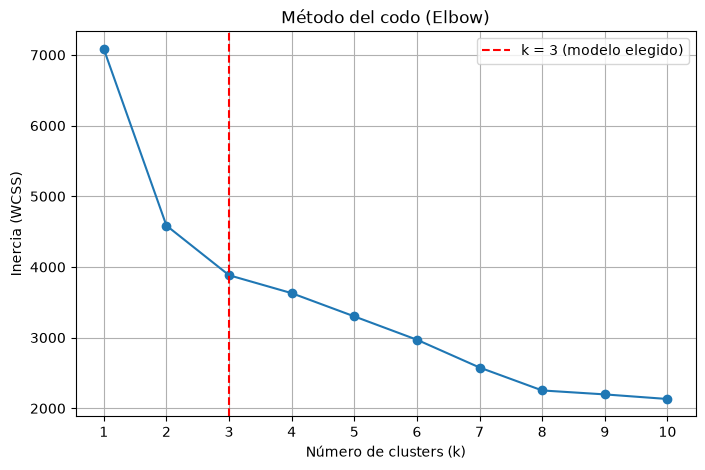

In [3]:
inercias = []
rango_k = range(1, 11)

for k in rango_k:
    modelo = KMeans(n_clusters=k, random_state=42)
    modelo.fit(X_scaled)
    inercias.append(modelo.inertia_)

for k, inercia in zip(rango_k, inercias):
    print(f'k={k:2d}  inercia={inercia:10.2f}')

plt.figure(figsize=(8, 5))
plt.plot(rango_k, inercias, marker='o')
plt.axvline(x=3, color='red', linestyle='--', label='k = 3 (modelo elegido)')
plt.title('Método del codo (Elbow)')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Inercia (WCSS)')
plt.xticks(list(rango_k))
plt.legend()
plt.grid(True)
plt.show()

**Interpretación:** la inercia baja de 7084 (k=1) a 4586 (k=2) y a 3883 (k=3). A partir de k=3 las caídas son mucho más chicas y parejas (3629 con k=4, 3301 con k=5), así que la curva forma el codo entre k=2 y k=3. Agregar más clusters después de 3 aporta poca mejora, por lo que el método del codo respalda la elección de 3 clusters.

## 3. PCA: reducción a 3 componentes principales

In [4]:
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2', 'PC3'])
df_pca['cluster'] = labels

print('Varianza explicada por componente:', pca.explained_variance_ratio_.round(4))
print('Varianza explicada acumulada:', round(pca.explained_variance_ratio_.sum(), 4))

# Peso de cada variable original en cada componente
cargas = pd.DataFrame(pca.components_.T, index=df.columns, columns=['PC1', 'PC2', 'PC3'])
display(cargas.round(3))

df_pca.head()

Varianza explicada por componente: [0.4676 0.1178 0.0964]
Varianza explicada acumulada: 0.6817


,PC1,PC2,PC3
CRIM,0.242,-0.066,0.395
ZN,-0.245,-0.148,0.395
INDUS,0.332,0.127,-0.066
CHAS,-0.005,0.411,-0.125
NOX,0.325,0.254,-0.046
RM,-0.203,0.434,0.353
AGE,0.297,0.260,-0.201
DIS,-0.298,-0.359,0.157
RAD,0.303,0.031,0.419
TAX,0.324,0.009,0.343


,PC1,PC2,PC3,cluster
0,-2.087344,0.492853,-0.335991,0
1,-1.373382,-0.170924,-0.965964,2
2,-2.376553,0.914027,-0.090026,0
3,-2.837779,0.194870,0.060545,0
4,-2.772916,0.433299,0.064042,0


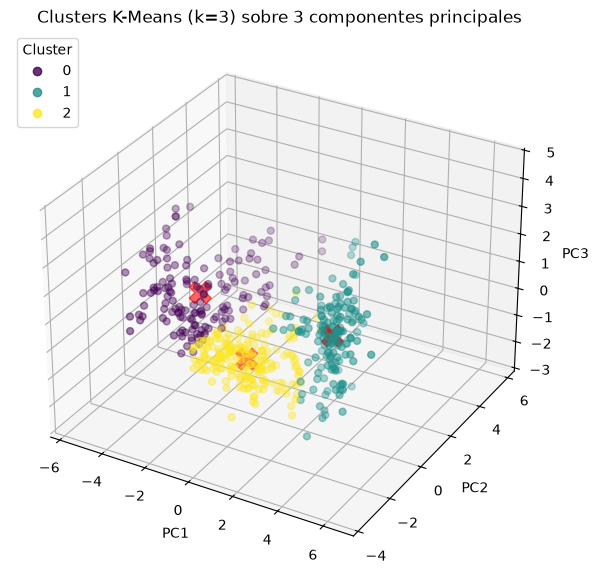

In [5]:
# Visualizacion 3D de los clusters en el espacio de las 3 componentes
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection='3d')

scatter = ax.scatter(df_pca['PC1'], df_pca['PC2'], df_pca['PC3'],
                     c=df_pca['cluster'], cmap='viridis', s=25, alpha=0.8)

# Centroides de K-Means proyectados al espacio PCA
centroides_pca = pca.transform(kmeans.cluster_centers_)
ax.scatter(centroides_pca[:, 0], centroides_pca[:, 1], centroides_pca[:, 2],
           c='red', marker='X', s=250, label='Centroides')

ax.set_title('Clusters K-Means (k=3) sobre 3 componentes principales')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.legend(*scatter.legend_elements(), title='Cluster', loc='upper left')
plt.show()

## 4. Validación de clusters con el índice de silueta (Silhouette)

El coeficiente de silueta va de -1 a 1: cerca de 1 indica clusters compactos y bien separados, cerca de 0 indica clusters superpuestos y negativo indica puntos mal asignados.

Indice de silueta para k=3: 0.2339

Silueta promedio por cluster:
0    0.1520
1    0.2268
2    0.2979
dtype: float64
k= 2  silueta=0.3501
k= 3  silueta=0.2339
k= 4  silueta=0.2439
k= 5  silueta=0.2455
k= 6  silueta=0.2258
k= 7  silueta=0.2517
k= 8  silueta=0.2580
k= 9  silueta=0.2270
k=10  silueta=0.2207


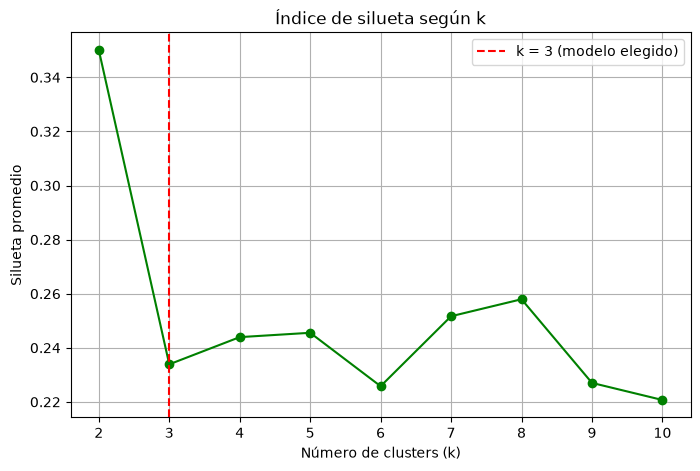

In [6]:
# Silueta del modelo pedido (k=3)
sil_k3 = silhouette_score(X_scaled, labels)
print(f'Indice de silueta para k=3: {sil_k3:.4f}')

# Silueta promedio por cluster
valores_sil = silhouette_samples(X_scaled, labels)
print('\nSilueta promedio por cluster:')
print(pd.Series(valores_sil).groupby(labels).mean().round(4))

# Comparacion con otros valores de k
siluetas = []
rango_k_sil = range(2, 11)  # la silueta necesita al menos 2 clusters
for k in rango_k_sil:
    etiquetas_k = KMeans(n_clusters=k, random_state=42).fit_predict(X_scaled)
    siluetas.append(silhouette_score(X_scaled, etiquetas_k))

for k, s in zip(rango_k_sil, siluetas):
    print(f'k={k:2d}  silueta={s:.4f}')

plt.figure(figsize=(8, 5))
plt.plot(rango_k_sil, siluetas, marker='o', color='green')
plt.axvline(x=3, color='red', linestyle='--', label='k = 3 (modelo elegido)')
plt.title('Índice de silueta según k')
plt.xlabel('Número de clusters (k)')
plt.ylabel('Silueta promedio')
plt.xticks(list(rango_k_sil))
plt.legend()
plt.grid(True)
plt.show()

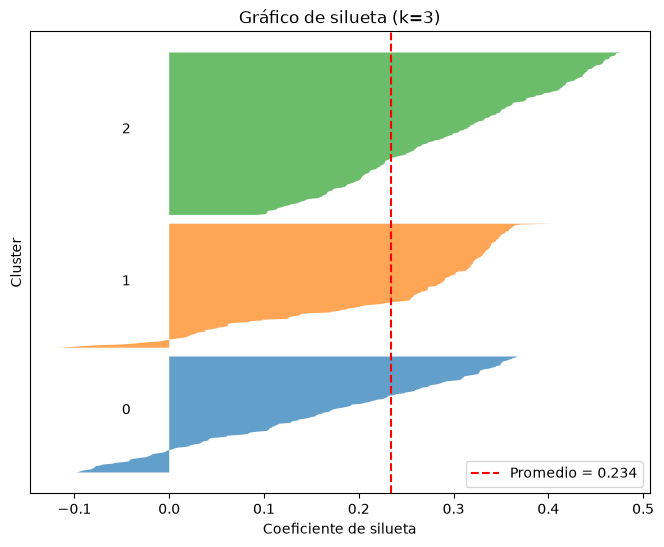

In [7]:
# Grafico de silueta por muestra para k=3
fig, ax = plt.subplots(figsize=(8, 6))
y_inf = 10
for c in range(3):
    valores_c = np.sort(valores_sil[labels == c])
    y_sup = y_inf + len(valores_c)
    ax.fill_betweenx(np.arange(y_inf, y_sup), 0, valores_c, alpha=0.7)
    ax.text(-0.05, y_inf + len(valores_c) / 2, str(c))
    y_inf = y_sup + 10

ax.axvline(x=sil_k3, color='red', linestyle='--', label=f'Promedio = {sil_k3:.3f}')
ax.set_title('Gráfico de silueta (k=3)')
ax.set_xlabel('Coeficiente de silueta')
ax.set_ylabel('Cluster')
ax.set_yticks([])
ax.legend()
plt.show()

**Interpretación:** el índice de silueta para k=3 es **0.234**. Es positivo, así que la mayoría de las casas están más cerca de su propio cluster que del vecino, pero está lejos de 1: los grupos se solapan bastante, algo esperable con 14 variables correlacionadas. Por cluster, el 2 es el más cohesionado (0.298) y el 0 el más difuso (0.152).

Comparando valores de k, la silueta más alta es la de k=2 (0.350); entre k=3 y k=10 los valores quedan todos entre 0.22 y 0.26. Es decir, la silueta sugiere que la división más nítida es en 2 grupos, mientras que el codo marca 3. Con k=3 se gana un grupo intermedio interpretable (ver perfiles del punto 1) a costa de algo de separación.

## 5. Extra (pregunta teórica 3): eliminar stop words con NLTK

In [8]:
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Descargar recursos (solo la primera vez)
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')  # necesario en versiones nuevas de NLTK

texto = 'Este es un ejemplo de texto en el que vamos a eliminar las stop words'

# Conjunto de stop words en español ('english' para textos en ingles)
stop_words = set(stopwords.words('spanish'))

# Tokenizar el texto en palabras
tokens = word_tokenize(texto.lower(), language='spanish')

# Quedarse solo con las palabras que no son stop words
tokens_filtrados = [palabra for palabra in tokens if palabra not in stop_words]

print('Original:', tokens)
print('Sin stop words:', tokens_filtrados)

Original: ['este', 'es', 'un', 'ejemplo', 'de', 'texto', 'en', 'el', 'que', 'vamos', 'a', 'eliminar', 'las', 'stop', 'words']
Sin stop words: ['ejemplo', 'texto', 'vamos', 'eliminar', 'stop', 'words']
